In [246]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from sklearn.preprocessing import PowerTransformer

# EDA - AIS

<b>Note:</b> This dataset isn't in the repository, it is too large. The link is here https://www.kaggle.com/datasets/nguyenductuandat/lalb-ais-port-congestion-62023-122025?select=ais_2023_2025_clean.parquet

This is also a good time to note the name I used for the file below, which starts with zz. By itself, this doesn't mean anything, but I put a rule in the "gitignore" file to ignore any files that start with zz. Gitignore is a list of stuff that git should ignore, so if we have a massive file like this, we can keep it out of the uplpoads and avoid having git choke on a file it can't handle.

In [ ]:
file_path = "data/zzais_2023_2025_clean.parquet"
#file_path_new = "data/zzais_2025H2.parquet"
df = pd.read_parquet(file_path)
#df2 = pd.read_parquet(file_path_new)
flagDrops = ["length_imputed_flag", "width_imputed_flag", "sog_imputed_flag", "cog_imputed_flag", "draft_imputed_flag"]
df.drop(columns=flagDrops, inplace=True)
#df2.drop(columns=flagDrops, inplace=True)

# Note - if it is slow, adjust this to reduce sample size used
INITIAL_SAMPLE_RATIO = .1
df = df.sample(frac=INITIAL_SAMPLE_RATIO, random_state=9)
df.head()

,hour_key,mmsi,visit_id,base_date_time,longitude,latitude,sog,cog,heading,vessel_name,...,ship_density,avg_port_speed,port_throughput,delay_minutes,wind_speed_10m,wind_gusts_10m,precipitation,weather_code,wave_height,swell_wave_height
6928726,2025-08-21 00:00:00,366855000,2,2025-08-21 00:08:49+00:00,-118.26790,33.75997,0.0,66.2,197.0,FLORIDA,...,49,0.733627,1,194.50,9.7,30.6,0.0,3.0,0.74,0.60
9249359,2024-02-19 20:00:00,369225000,8,2024-02-19 20:29:33+00:00,-118.15424,33.73636,0.2,237.5,143.0,UTAH VOYAGER,...,47,0.111542,0,219.60,19.6,46.8,0.7,53.0,1.78,1.52
20145952,2025-02-01 20:00:00,636020257,1,2025-02-01 20:11:49+00:00,-118.21406,33.75259,0.0,359.0,359.0,SEATTLE EXPRESS,...,54,0.305571,0,181.00,0.6,12.6,0.0,3.0,0.56,0.42
16099330,2025-04-21 07:00:00,538009098,1,2025-04-21 07:19:43+00:00,-118.25950,33.71502,7.6,295.1,294.0,NORD VICTORIOUS,...,47,0.798221,0,1012.45,4.6,14.4,0.0,2.0,0.74,0.50
20931184,2025-10-11 12:00:00,636023225,1,2025-10-11 12:31:41+00:00,-118.21644,33.74512,6.0,326.9,325.0,SWEET PEA LEADER,...,41,2.877407,2,275.75,4.4,5.4,0.0,0.0,1.16,0.90


In [248]:
TARGET_COL = "delay_minutes"
df = df[df[TARGET_COL] >= 0]

OUTLIER_Y = False
DO_PAIRPLOT = False
DO_VIF = False
DO_OUTLIER_PLOT = False
DO_Y_TRANSFORM = True

In [249]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1815573 entries, 6928726 to 14557213
Data columns (total 48 columns):
 #   Column                 Dtype              
---  ------                 -----              
 0   hour_key               datetime64[us]     
 1   mmsi                   int32              
 2   visit_id               int64              
 3   base_date_time         datetime64[us, UTC]
 4   longitude              float64            
 5   latitude               float64            
 6   sog                    float64            
 7   cog                    float64            
 8   heading                float64            
 9   vessel_name            object             
 10  imo                    object             
 11  call_sign              object             
 12  vessel_type            int32              
 13  status                 float64            
 14  length                 int32              
 15  width                  int32              
 16  draft           

In [250]:
df.describe(include='all').T

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
hour_key,1815573,NaN,NaN,NaN,2024-08-30 03:06:24.295206,2023-06-01 00:00:00,2024-01-16 13:00:00,2024-08-23 21:00:00,2025-04-10 09:00:00,2025-12-31 23:00:00,NaN
mmsi,1815573.0,NaN,NaN,NaN,433563475.340963,205663000.0,353428000.0,416465000.0,538009582.0,636093309.0,127877787.536188
visit_id,1815573.0,NaN,NaN,NaN,2.302041,1.0,1.0,1.0,3.0,50.0,2.71697
base_date_time,1815573,NaN,NaN,NaN,2024-08-30 03:36:05.750328+00:00,2023-06-01 00:00:02+00:00,2024-01-16 13:17:52+00:00,2024-08-23 21:11:38+00:00,2025-04-10 09:17:50+00:00,2025-12-31 23:59:37+00:00,NaN
longitude,1815573.0,NaN,NaN,NaN,-118.223398,-118.5,-118.25657,-118.224,-118.20226,-118.0,0.059718
latitude,1815573.0,NaN,NaN,NaN,33.728376,33.5,33.72596,33.7435,33.75485,33.9,0.044421
sog,1815563.0,NaN,NaN,NaN,0.984601,0.0,0.0,0.0,0.1,25.2,2.69677
cog,1815573.0,NaN,NaN,NaN,183.50814,0.0,92.3,189.3,273.0,359.9,106.159366
heading,1761507.0,NaN,NaN,NaN,180.55067,0.0,75.0,200.0,252.0,359.0,102.979575
vessel_name,1815573,2492,CAPE ISABEL,29045,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [251]:
LATCOL = "latitude"
LONCOL = "longitude"

<Axes: xlabel='longitude', ylabel='latitude'>

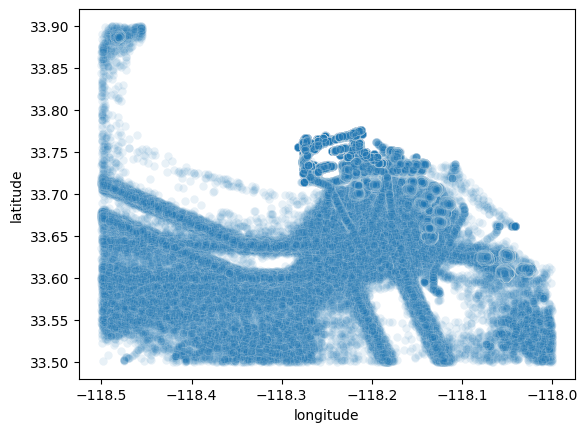

In [252]:
sns.scatterplot(data=df, x=LONCOL, y=LATCOL, alpha=0.1)

## Process Data

### Make Categorical

Some values in our dataset are categorical, but they are not stored with label encoding. We will convert these values to categorical values, which will allow us to use one-hot encoding later on.

In [253]:
make_cat = ["is_in_waiting_area",
            #"vessel_size_category",
            'weather_code',
            "vessel_type",
            'is_weekend', 
            'is_night_shift', 
            'is_gate_hours',
            'status'
            ]

for col in make_cat:
    df[col] = df[col].astype('object')

df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1815573 entries, 6928726 to 14557213
Data columns (total 48 columns):
 #   Column                 Dtype              
---  ------                 -----              
 0   hour_key               datetime64[us]     
 1   mmsi                   int32              
 2   visit_id               int64              
 3   base_date_time         datetime64[us, UTC]
 4   longitude              float64            
 5   latitude               float64            
 6   sog                    float64            
 7   cog                    float64            
 8   heading                float64            
 9   vessel_name            object             
 10  imo                    object             
 11  call_sign              object             
 12  vessel_type            object             
 13  status                 object             
 14  length                 int32              
 15  width                  int32              
 16  draft           

### Sin/Cos Transformations 

We don't need to do this, since it has been done for us, but we can illustrate it here. We can take months, day, and hour, and generate new sin/cos features for them manually. 

In [254]:
cols_to_transform = ["month", "day_of_week", "hour"]
df[cols_to_transform].head()

,month,day_of_week,hour
6928726,8,5,0
9249359,2,2,20
20145952,2,7,20
16099330,4,2,7
20931184,10,7,12


In [256]:
df_trans_example = df.copy().sample(frac=.01)

for col in cols_to_transform:
    df_trans_example[col + "_sin_MAN"] = np.sin(2 * np.pi * df_trans_example[col] / df_trans_example[col].max())
    df_trans_example[col + "_cos_MAN"] = np.cos(2 * np.pi * df_trans_example[col] / df_trans_example[col].max())
    #df_trans_example.drop(columns=[col], inplace=True)

df_trans_example.info()

<class 'pandas.core.frame.DataFrame'>
Index: 18156 entries, 10216530 to 6273686
Data columns (total 54 columns):
 #   Column                 Non-Null Count  Dtype              
---  ------                 --------------  -----              
 0   hour_key               18156 non-null  datetime64[us]     
 1   mmsi                   18156 non-null  int32              
 2   visit_id               18156 non-null  int64              
 3   base_date_time         18156 non-null  datetime64[us, UTC]
 4   longitude              18156 non-null  float64            
 5   latitude               18156 non-null  float64            
 6   sog                    18156 non-null  float64            
 7   cog                    18156 non-null  float64            
 8   heading                17633 non-null  float64            
 9   vessel_name            18156 non-null  object             
 10  imo                    18058 non-null  object             
 11  call_sign              18156 non-null  object     

### Outliers

#### Detecting Outliers

In [257]:
filterSDT = 3
idCols = ['mmsi', 'visit_id', 'imo', 'vessel_name', 'call_sign']
colsLessID = df.drop(columns=idCols)
plotCols = 4

numericCols = colsLessID.select_dtypes(include=['float64', 'int64', 'int32', 'float32']).columns
categoricalCols = colsLessID.select_dtypes(include=['object', 'category']).columns
dateTimeCols = colsLessID.select_dtypes(include=['datetime64', "datetime64[us, UTC]"]).columns
leftoverCols = colsLessID.select_dtypes(exclude=['float64', 'int64', 'object', 'int32', 'float32', "datetime64", "datetime64[us, UTC]"]).columns

print("Numeric Columns:", len(numericCols), numericCols.tolist())
print("Categorical Columns:", len(categoricalCols), categoricalCols.tolist())
print("DateTime Columns:", len(dateTimeCols), dateTimeCols.tolist())
print("ID Columns:", len(idCols), idCols)
print("Leftover Columns:", len(leftoverCols), leftoverCols.tolist())

Numeric Columns: 33 ['longitude', 'latitude', 'sog', 'cog', 'heading', 'length', 'width', 'draft', 'vessel_area', 'dimension_ratio', 'draft_to_length_ratio', 'hour', 'day_of_week', 'month', 'hour_sin', 'hour_cos', 'day_of_week_sin', 'day_of_week_cos', 'month_sin', 'month_cos', 'distance_to_port', 'heading_error', 'acceleration', 'time_in_zone_hours', 'ship_density', 'avg_port_speed', 'port_throughput', 'delay_minutes', 'wind_speed_10m', 'wind_gusts_10m', 'precipitation', 'wave_height', 'swell_wave_height']
Categorical Columns: 8 ['vessel_type', 'status', 'transceiver', 'is_weekend', 'is_night_shift', 'is_gate_hours', 'is_in_waiting_area', 'weather_code']
DateTime Columns: 2 ['hour_key', 'base_date_time']
ID Columns: 5 ['mmsi', 'visit_id', 'imo', 'vessel_name', 'call_sign']
Leftover Columns: 0 []


In [258]:
def detect_outliers(df, column):
    mean = df[column].mean()
    std_dev = df[column].std()
    outliersHigh = df[df[column] > mean + filterSDT * std_dev]
    outliersLow = df[df[column] < mean - filterSDT * std_dev]
    outliers = pd.concat([outliersHigh, outliersLow])
    return outliers

hasOutliers = []
for col in numericCols:
    outliers = detect_outliers(df, col)
    print(f"Outliers in {col}: {len(outliers)}")
    if len(outliers) > 0:
        hasOutliers.append(col)

Outliers in longitude: 44332
Outliers in latitude: 30800
Outliers in sog: 84925
Outliers in cog: 0
Outliers in heading: 0
Outliers in length: 0
Outliers in width: 6826
Outliers in draft: 9037
Outliers in vessel_area: 0
Outliers in dimension_ratio: 28626
Outliers in draft_to_length_ratio: 9091
Outliers in hour: 0
Outliers in day_of_week: 0
Outliers in month: 0
Outliers in hour_sin: 0
Outliers in hour_cos: 0
Outliers in day_of_week_sin: 0
Outliers in day_of_week_cos: 0
Outliers in month_sin: 0
Outliers in month_cos: 0
Outliers in distance_to_port: 50036
Outliers in heading_error: 0
Outliers in acceleration: 93942
Outliers in time_in_zone_hours: 29029
Outliers in ship_density: 3521
Outliers in avg_port_speed: 9039
Outliers in port_throughput: 54232
Outliers in delay_minutes: 53314
Outliers in wind_speed_10m: 25764
Outliers in wind_gusts_10m: 21328
Outliers in precipitation: 18421
Outliers in wave_height: 42984
Outliers in swell_wave_height: 30298


In [259]:
if DO_OUTLIER_PLOT:
    print("Creating outlier plots...")
    outlierRows = np.ceil(len(hasOutliers) / plotCols)
    fig, ax = plt.subplots(int(outlierRows), plotCols, figsize=(12, 3 * outlierRows))
    for i, col in enumerate(hasOutliers):
        row = i // plotCols
        col_idx = i % plotCols
        sns.histplot(data=df, x=col, ax=ax[row, col_idx], kde=True)
    ## Add vertical lines for mean and outlier thresholds
    mean = df[col].mean()
    std_dev = df[col].std()
    ax[row, col_idx].axvline(mean, color='r', linestyle='--', label='Mean')
    ax[row, col_idx].axvline(mean + filterSDT * std_dev, color='g', linestyle='--', label='Mean + 3SD')
    ax[row, col_idx].axvline(mean - filterSDT * std_dev, color='g', linestyle='--', label='Mean - 3SD')
#fig.legend()

### Set Outlier Filters

In [260]:
# Hard Limits

'''dimension_ratio_cut = 13
avg_port_speed_cut = 55
acceleration_cut = 5
distance_to_port_cut = 4
sog_cut = .2'''


std_cut = 2.75

print("Removing outliers using a threshold of", std_cut, "standard deviations from the mean.")
print("Size pre-removal:", len(df))

for col in numericCols:
    mean = df[col].mean()
    std_dev = df[col].std()
    upper_limit = mean + std_cut * std_dev
    lower_limit = mean - std_cut * std_dev
    df = df[(df[col] <= upper_limit) & (df[col] >= lower_limit)]



Y_CUT = 2000
if OUTLIER_Y:
    print("Filtering target variable to be less than", Y_CUT)
    df = df[df[TARGET_COL] < Y_CUT]

print("Size post-removal:", len(df))

Removing outliers using a threshold of 2.75 standard deviations from the mean.
Size pre-removal: 1815573
Size post-removal: 1207079


#### Examine Target

<Axes: ylabel='Count'>

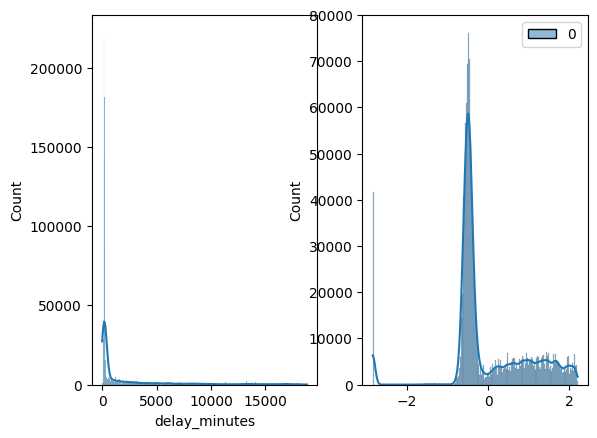

In [261]:
fig, ax = plt.subplots(1, 2)
sns.histplot(data=df[TARGET_COL], kde=True, ax=ax[0])
sns.histplot(data=PowerTransformer().fit_transform(df[[TARGET_COL]]), kde=True, ax=ax[1])

### Transform Target

In [262]:
if DO_Y_TRANSFORM:
    print("Transforming target variable using PowerTransformer.")
    pt = PowerTransformer()
    df[TARGET_COL] = pt.fit_transform(df[[TARGET_COL]])

Transforming target variable using PowerTransformer.


### Distinct Values

In [263]:
lowCut = 100
lowDistinct = []
for col in numericCols:
    numValues = df[col].nunique()
    #print(f"Column: {col}, Distinct Values: {numValues}")
    if numValues < lowCut:
        lowDistinct.append( (col, numValues) )

for item in lowDistinct:
    print(f"Column: {item[0]}, Distinct Values: {item[1]}")

Column: sog, Distinct Values: 62
Column: width, Distinct Values: 41
Column: hour, Distinct Values: 24
Column: day_of_week, Distinct Values: 7
Column: month, Distinct Values: 12
Column: hour_sin, Distinct Values: 22
Column: hour_cos, Distinct Values: 22
Column: day_of_week_sin, Distinct Values: 7
Column: day_of_week_cos, Distinct Values: 7
Column: month_sin, Distinct Values: 11
Column: month_cos, Distinct Values: 11
Column: ship_density, Distinct Values: 32
Column: port_throughput, Distinct Values: 3
Column: precipitation, Distinct Values: 11
Column: wave_height, Distinct Values: 73
Column: swell_wave_height, Distinct Values: 65


### Unique Visit

In the data, there are multiple rows for each visit. There is a visit ID, but it is a per vessel thing. I want something that uniquely identifies an individual visit by a boat. I'll do this by simply concatenating the vessel and the visit into a new column. I'm not 100% how much I'll need this right now, but I think it may be useful - at a minimum, if I want to map this, I'll need a unique identifier to plot routes. 

In [264]:
df['unique_visit'] = df['mmsi'].astype(str) + '_' + df['visit_id'].astype(str)

### Verify

We have not filtered outliers away. At this point, we should check the data to see what it looks like now, as well as to see if we should go back and adjust what we've done to this point. 

<b>In general, checking the data as we process it in cleaning is a good idea. We may make changes based on what we see, or we may find we need to add or remove steps. </b>

In [265]:
sampleRatio = .01
pairPlotData = df[numericCols].sample(frac=sampleRatio)
if DO_PAIRPLOT:
    print("Creating pairplot with sample ratio of", sampleRatio)
    sns.pairplot(data=pairPlotData)

### Multicollinearity

I think that we have some redundant columns, with high multicollinearity between them. At a minimum, I know we have the sin/cos time transformations that will be highly correlated with the original time. As well, I know that some of the vessel size columns are constructed from each other, so we'll have some multicollinearity there as well.

In [266]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

def makeVIFtable(df, numericCols, sampleFrac=1.0):
    if sampleFrac < 1.0:
        df = df.sample(frac=sampleFrac)
    vif_data = pd.DataFrame()
    vif_data["feature"] = numericCols
    vif_data["VIF"] = [variance_inflation_factor(df[numericCols].values, i) for i in range(len(numericCols))]
    vif_data = vif_data.sort_values(by="VIF", ascending=False)
    return vif_data

if DO_VIF:
    print("Calculating VIFs for numeric columns...")
    vifs = makeVIFtable(df.dropna(), numericCols, .5)
    vifs

### Feature Selection

Based on the multicollinearity as well as some domain knowledge, we will narrow down the features we will use in our model. This is going to be partially based on metrics, partially based on domain knowledge, and partially based on what we think will be useful for our model. We will look more closely at selecting features next semester. 

In [267]:
droppedCols = ["hour", "day_of_week", "month", "unique_visit", "hour_key", "base_date_time", "heading_error"]
droppedCols = droppedCols + idCols + [TARGET_COL]
predX = df.drop(columns=droppedCols)
predY = df[TARGET_COL]
predX.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1207079 entries, 6928726 to 14557213
Data columns (total 36 columns):
 #   Column                 Non-Null Count    Dtype  
---  ------                 --------------    -----  
 0   longitude              1207079 non-null  float64
 1   latitude               1207079 non-null  float64
 2   sog                    1207079 non-null  float64
 3   cog                    1207079 non-null  float64
 4   heading                1207079 non-null  float64
 5   vessel_type            1207079 non-null  object 
 6   status                 1206766 non-null  object 
 7   length                 1207079 non-null  int32  
 8   width                  1207079 non-null  int32  
 9   draft                  1207079 non-null  float64
 10  transceiver            1207079 non-null  object 
 11  vessel_area            1207079 non-null  int32  
 12  dimension_ratio        1207079 non-null  float64
 13  draft_to_length_ratio  1207079 non-null  float64
 14  hour_sin        

### Revisit Multicollinearity - Corrlation Matrix

Normally, we'd repeat the multicollinearity check, adjust, repeat, etc a few times. I'm just going to do it once, in interest of time. Also, I'll use a correlation matrix to look for multicollinearity visually. 

<Axes: >

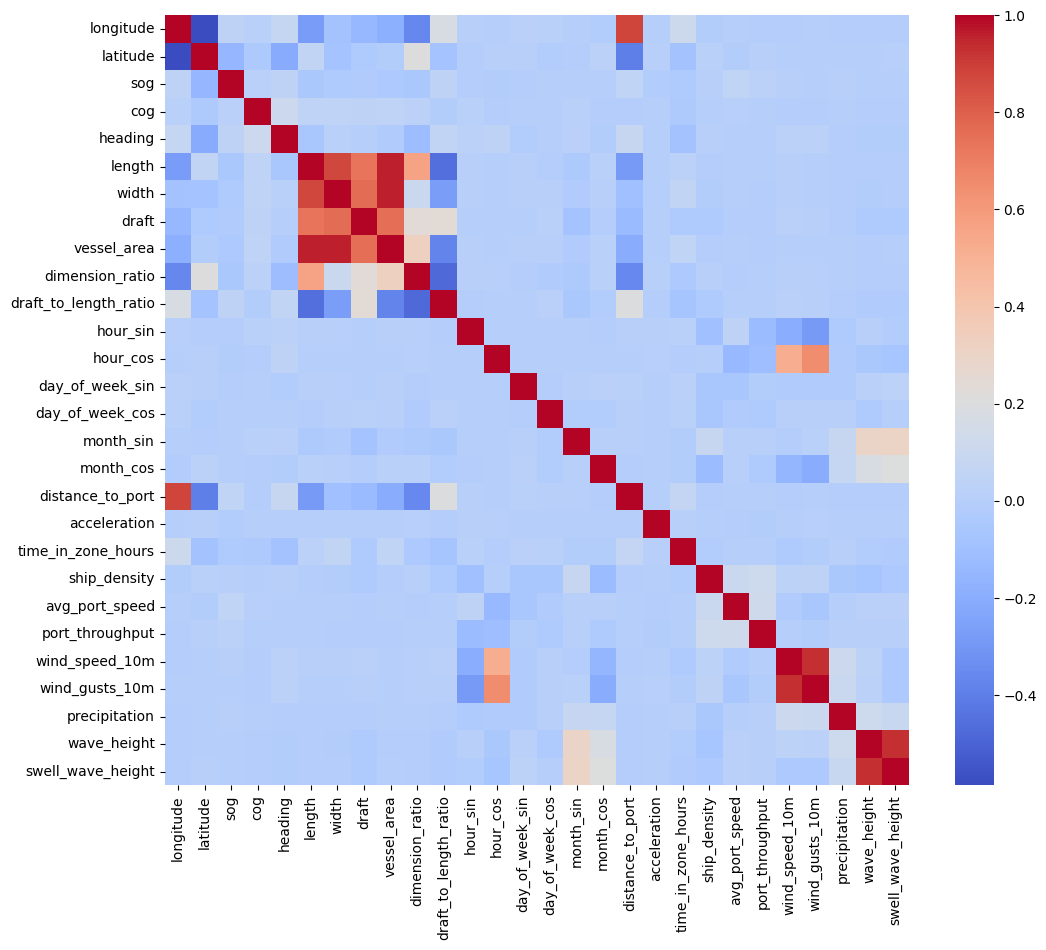

In [268]:
x_corr_matrix = finalNumCols = predX.select_dtypes(include=['float64', 'int64', 'int32', 'float32']).corr()
plt.figure(figsize=(12, 10))
sns.heatmap(x_corr_matrix, annot=False, cmap="coolwarm", cbar=True)

### Finalize Columns for Model

In [269]:
drops = ["wind_gusts_10m"]
predX.drop(columns=drops, inplace=True)

finalNumCols = predX.select_dtypes(include=['float64', 'int64', 'int32', 'float32']).columns
finalCatCols = predX.select_dtypes(include=['object', 'category']).columns
finalLeftoverCols = predX.select_dtypes(exclude=['float64', 'int64', 'object', 'int32', 'float32', "datetime64", "datetime64[us, UTC]"]).columns

print("Final Numeric Columns:", len(finalNumCols), finalNumCols.tolist())
print("Final Categorical Columns:", len(finalCatCols), finalCatCols.tolist())
print("Final Leftover Columns:", len(finalLeftoverCols), finalLeftoverCols.tolist())

Final Numeric Columns: 27 ['longitude', 'latitude', 'sog', 'cog', 'heading', 'length', 'width', 'draft', 'vessel_area', 'dimension_ratio', 'draft_to_length_ratio', 'hour_sin', 'hour_cos', 'day_of_week_sin', 'day_of_week_cos', 'month_sin', 'month_cos', 'distance_to_port', 'acceleration', 'time_in_zone_hours', 'ship_density', 'avg_port_speed', 'port_throughput', 'wind_speed_10m', 'precipitation', 'wave_height', 'swell_wave_height']
Final Categorical Columns: 8 ['vessel_type', 'status', 'transceiver', 'is_weekend', 'is_night_shift', 'is_gate_hours', 'is_in_waiting_area', 'weather_code']
Final Leftover Columns: 0 []


### Pipeline Steps

With outliers gone and data explored, we can process most of the rest of the work via a pipeline. We can base the steps we'll need on what we have seen above:
<ul>
<li> Encoding - we have categorical values, so we'll need to one-hot encode them. </li>
<li> Scaling - we have numeric values on very different scales, so we'll need to scale them. </li>
<li> Imputation - we have missing values, so we'll need to impute them. </li>
</ul>

### Mixed Data Types

We have some categorical values as well as some numeric values. These require different treatment, so we need some way to have a pipeline that can handle two paths of data prep. The ColumnTransformer tool is basically this, a pipeline that can have branching, which sends some data down one path and some data down another path before rejoining it and proceeding as normal with modelling.

#### ColumnTransformer

The ColumnTransformer is in the pipeline family and mostly works in the same way, the big exception is that it allows for branching, so that different columns can be processed differently. 

In the implementation, the main changes are that:
<ul>
<li> The column transformer contains other pipelines as parts. So we can construct a pipeline for each division of data, in our case, numeric and categorical. </li>
<li> We must specify which columns go down which path, which is the new addition to the step-by-step construction of a pipeline. </li>
<li> The ColumnTransformer will merge the results of the split back together, we'll add this to a new pipeline as a 'preprocessor' step, which will then be fed to the model. </li>
</ul>

In general, the sklearn pipeline objects can be connected together in almost any arrangement, so we can have pipelines within pipelines, and we can have branching pipelines. The structure below is a good template that can handle almost all of the scenarios we may encounter with minimal changes.

In [270]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder
from sklearn.metrics import mean_squared_error, root_mean_squared_error
from sklearn.impute import SimpleImputer

numericalPipe = Pipeline(steps=[
    ('imputerNum', SimpleImputer(strategy='mean')),
    ('scaler', MinMaxScaler())
])
categoricalPipe = Pipeline(steps=[
    ('imputerCat', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

fullCTpipe = ColumnTransformer(
    transformers=[
        ('num', numericalPipe, finalNumCols),
        ('cat', categoricalPipe, finalCatCols)
    ]
)

finalPipe = Pipeline(steps=[
    ('preprocessor', fullCTpipe),
    ('regressor', LinearRegression())
])

X_train, X_test, y_train, y_test = train_test_split(predX, predY, test_size=0.2)

finalPipe.fit(X_train, y_train)
test_score = finalPipe.score(X_test, y_test)
testRMSE = root_mean_squared_error(y_test, finalPipe.predict(X_test))
train_score = finalPipe.score(X_train, y_train)
trainRMSE = root_mean_squared_error(y_train, finalPipe.predict(X_train))

print(f"Train Score: {train_score:.4f}, Train RMSE: {trainRMSE:.4f}")
print(f"Test Score: {test_score:.4f}, Test RMSE: {testRMSE:.4f}")


Train Score: 0.3649, Train RMSE: 0.7970
Test Score: 0.3666, Test RMSE: 0.7955


### Improvements/Simplification

The baseline model isn't great, there are a few things I'm going to try to improve it. First, because the model above has a very large number of features, I'm going to reduce it and observe performance. This is going to mostly be based on some domain knowledge, I am targeting mainly things that I know/can read as being redundant to each other. Later, we will look at more advanced feature selection methods. 

In [271]:
predX.columns

Index(['longitude', 'latitude', 'sog', 'cog', 'heading', 'vessel_type',
       'status', 'length', 'width', 'draft', 'transceiver', 'vessel_area',
       'dimension_ratio', 'draft_to_length_ratio', 'hour_sin', 'hour_cos',
       'day_of_week_sin', 'day_of_week_cos', 'month_sin', 'month_cos',
       'is_weekend', 'is_night_shift', 'is_gate_hours', 'distance_to_port',
       'is_in_waiting_area', 'acceleration', 'time_in_zone_hours',
       'ship_density', 'avg_port_speed', 'port_throughput', 'wind_speed_10m',
       'precipitation', 'weather_code', 'wave_height', 'swell_wave_height'],
      dtype='object')

In [272]:
droppedColsImprove = ['longitude', 'latitude','heading', 'length', 'width', 'draft',
                      'acceleration', ]

predX_imp1 = predX.drop(columns=droppedColsImprove)

trainX_imp1, testX_imp1, trainY_imp1, testY_imp1 = train_test_split(predX_imp1, predY, test_size=0.2)

pipe_num_imp1 = Pipeline(steps=[
    ('imputerNum', SimpleImputer(strategy='mean')),
    ('scaler', MinMaxScaler())
])
pipe_cat_imp1 = Pipeline(steps=[
    ('imputerCat', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

fullCTpipe_imp1 = ColumnTransformer(
    transformers=[
        ('num', pipe_num_imp1, finalNumCols.drop(droppedColsImprove)),
        ('cat', pipe_cat_imp1, finalCatCols)
    ]
)

pipe_imp1 = Pipeline(steps=[
    ('preprocessor', fullCTpipe_imp1),
    ('regressor', LinearRegression())
])

pipe_imp1.fit(trainX_imp1, trainY_imp1)
test_score_imp1 = pipe_imp1.score(testX_imp1, testY_imp1)
testRMSE_imp1 = root_mean_squared_error(testY_imp1, pipe_imp1.predict(testX_imp1))
train_score_imp1 = pipe_imp1.score(trainX_imp1, trainY_imp1)
trainRMSE_imp1 = root_mean_squared_error(trainY_imp1, pipe_imp1.predict(trainX_imp1))

print(f"Train Score: {train_score_imp1:.4f}, Train RMSE: {trainRMSE_imp1:.4f}")
print(f"Test Score: {test_score_imp1:.4f}, Test RMSE: {testRMSE_imp1:.4f}")

Train Score: 0.3558, Train RMSE: 0.8028
Test Score: 0.3547, Test RMSE: 0.8028


##### Continue Improving

The model still isn't amazing, but it hasn't gotten worse. I'm going to look for variable importance using statsmodels and p-values, and use that to help me trim the dataset down even further. 

In [281]:
import statsmodels.api as sm
from scipy import sparse

preprocessor = pipe_imp1.named_steps["preprocessor"]
train_prepared = preprocessor.transform(trainX_imp1)
if sparse.issparse(train_prepared):
    train_prepared = train_prepared.toarray()

feature_names = preprocessor.get_feature_names_out()
encoder = preprocessor.named_transformers_["cat"].named_steps["onehot"]
category_start = preprocessor.output_indices_["cat"].start

reference_indices = []
for categories in encoder.categories_:
    reference_indices.append(category_start)
    category_start += len(categories)

keep_features = np.ones(len(feature_names), dtype=bool)
keep_features[reference_indices] = False

train_sm = pd.DataFrame(
    train_prepared[:, keep_features],
    columns=feature_names[keep_features],
    index=trainX_imp1.index
)
train_sm = sm.add_constant(train_sm, has_constant="add")
statsmodel_imp1 = sm.OLS(trainY_imp1, train_sm).fit()

print(statsmodel_imp1.summary())

                            OLS Regression Results                            
Dep. Variable:          delay_minutes   R-squared:                       0.356
Model:                            OLS   Adj. R-squared:                  0.356
Method:                 Least Squares   F-statistic:                 1.006e+04
Date:                Tue, 17 Nov 2026   Prob (F-statistic):               0.00
Time:                        10:08:46   Log-Likelihood:            -1.1581e+06
No. Observations:              965663   AIC:                         2.316e+06
Df Residuals:                  965609   BIC:                         2.317e+06
Df Model:                          53                                         
Covariance Type:            nonrobust                                         
                                   coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------------
const           

#### Smaller Model

I'm going to shortcut some steps here and shrink the feature set down quite a bit. In reality, I did a few trials of remove, model, test, repeat. That makes for boring and long content, so I'll condense it. 

The decisions here were made by:
<ul>
<li> Domain knowledge - I am knowingly forcing it and estimating a bit here. </li>
<li> Statsmodels p-values - I used statsmodels to get p-values for the features. </li>
<li> Multicollinearity - Either via vif or a correlation matrix. </li>
</ul>

Again, we'll look more at feature selection methods later, so I'm not being overly specific here. 

In [282]:
cols = statsmodel_imp1.model.exog_names
colsDF = pd.DataFrame(cols, columns=["Column"])
colsDF["p_value"] = statsmodel_imp1.pvalues.values
colsDF.sort_values(by="p_value", ascending=False, inplace=True)
colsDF.head(60)

,Column,p_value
53,cat__weather_code_55.0,8.168008e-01
20,num__swell_wave_height,6.175433e-01
44,cat__is_night_shift_1,5.694932e-01
15,num__avg_port_speed,5.373961e-01
37,cat__status_3.0,5.372843e-01
22,cat__vessel_type_72,5.290070e-01
45,cat__is_gate_hours_1,4.822645e-01
3,num__vessel_area,3.099087e-01
41,cat__status_8.0,2.097341e-01
40,cat__status_6.0,1.979730e-01


In [283]:
predX_imp1.columns

Index(['sog', 'cog', 'vessel_type', 'status', 'transceiver', 'vessel_area',
       'dimension_ratio', 'draft_to_length_ratio', 'hour_sin', 'hour_cos',
       'day_of_week_sin', 'day_of_week_cos', 'month_sin', 'month_cos',
       'is_weekend', 'is_night_shift', 'is_gate_hours', 'distance_to_port',
       'is_in_waiting_area', 'time_in_zone_hours', 'ship_density',
       'avg_port_speed', 'port_throughput', 'wind_speed_10m', 'precipitation',
       'weather_code', 'wave_height', 'swell_wave_height'],
      dtype='object')

In [284]:
small_trial_cols = ["vessel_type",
                    "status",
                    "sog",
                    "time_in_zone_hours",
                    "distance_to_port",
                    "draft_to_length_ratio",
                    "dimension_ratio",
                    "vessel_area",
                    "ship_density"
                    ]

My small test dataset is partially judgement based, but makes sense. I have some stuff that measures how long they've waited, the size of ship (I assume you can only go to certain ports with certain size ships), how busy the port is, and how far you are. This sounds like a reasonable trial run. 

In the p-values above, we have many outputs for a column that went through one-hot encoding. I looked for patterns - if many of the outputs for a column had high p-values, that was a negative mark, if many were low, that was a positive mark. 

In [285]:
small_y = predY
small_X = predX_imp1[small_trial_cols]

small_num_cols = small_X.select_dtypes(include=['float64', 'int64', 'int32', 'float32']).columns
small_cat_cols = small_X.select_dtypes(include=['object', 'category']).columns

small_num_pipe = Pipeline(steps=[
    ('imputerNum', SimpleImputer(strategy='mean')),
    ('scaler', MinMaxScaler())
])

small_cat_pipe = Pipeline(steps=[
    ('imputerCat', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

small_fullCTpipe = ColumnTransformer(
    transformers=[
        ('num', small_num_pipe, small_num_cols),
        ('cat', small_cat_pipe, small_cat_cols)
    ]
)

small_pipe = Pipeline(steps=[
    ('preprocessor', small_fullCTpipe),
    #('regressor', LinearRegression())
])

prepped_small_X = small_pipe.fit_transform(small_X)
train_small_X, test_small_X, train_small_y, test_small_y = train_test_split(prepped_small_X, small_y, test_size=0.2)

In [286]:
from scipy import sparse

small_preprocessor = small_pipe.named_steps["preprocessor"]
small_feature_names = small_preprocessor.get_feature_names_out()
small_encoder = small_preprocessor.named_transformers_["cat"].named_steps["onehot"]

category_start = small_preprocessor.output_indices_["cat"].start
reference_indices = []
for categories in small_encoder.categories_:
    reference_indices.append(category_start)
    category_start += len(categories)

keep_features = np.ones(len(small_feature_names), dtype=bool)
keep_features[reference_indices] = False
print("Reference categories:", small_feature_names[reference_indices])

small_train_prepared = (
    train_small_X.toarray() if sparse.issparse(train_small_X) else train_small_X
)
small_train_sm = pd.DataFrame(
    small_train_prepared[:, keep_features],
    columns=small_feature_names[keep_features],
    index=train_small_y.index
)
small_train_sm = sm.add_constant(small_train_sm, has_constant="add")
small_sm_model = sm.OLS(train_small_y, small_train_sm).fit()
print(small_sm_model.summary())



Reference categories: ['cat__vessel_type_70' 'cat__status_0.0']
                            OLS Regression Results                            
Dep. Variable:          delay_minutes   R-squared:                       0.354
Model:                            OLS   Adj. R-squared:                  0.354
Method:                 Least Squares   F-statistic:                 1.828e+04
Date:                Tue, 17 Nov 2026   Prob (F-statistic):               0.00
Time:                        10:08:48   Log-Likelihood:            -1.1590e+06
No. Observations:              965663   AIC:                         2.318e+06
Df Residuals:                  965633   BIC:                         2.318e+06
Df Model:                          29                                         
Covariance Type:            nonrobust                                         
                                 coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------

### Final Pass

In [289]:
newDrops = ["vessel_area", "status"]

finalX = predX_imp1.drop(columns=newDrops)
finalY = predY

finalNumCols = finalX.select_dtypes(include=['float64', 'int64', 'int32', 'float32']).columns
finalCatCols = finalX.select_dtypes(include=['object', 'category']).columns

train_finalX, test_finalX, train_finalY, test_finalY = train_test_split(finalX, finalY, test_size=0.2)

pipe_num_final = Pipeline(steps=[
    ('imputerNum', SimpleImputer(strategy='mean')),
    ('scaler', MinMaxScaler())
])

pipe_cat_final = Pipeline(steps=[
    ('imputerCat', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

fullCTpipe_final = ColumnTransformer(
    transformers=[
        ('num', pipe_num_final, finalNumCols),
        ('cat', pipe_cat_final, finalCatCols)
    ]
)

pipe_final = Pipeline(steps=[
    ('preprocessor', fullCTpipe_final),
    ('regressor', LinearRegression())
])

pipe_final.fit(train_finalX, train_finalY)
test_score_final = pipe_final.score(test_finalX, test_finalY)
testRMSE_final = root_mean_squared_error(test_finalY, pipe_final.predict(test_finalX))
train_score_final = pipe_final.score(train_finalX, train_finalY)
trainRMSE_final = root_mean_squared_error(train_finalY, pipe_final.predict(train_finalX))

print(f"Train Score: {train_score_final:.4f}, Train RMSE: {trainRMSE_final:.4f}")
print(f"Test Score: {test_score_final:.4f}, Test RMSE: {testRMSE_final:.4f}")

Train Score: 0.3342, Train RMSE: 0.8165
Test Score: 0.3360, Test RMSE: 0.8129


## Exercise

Use the dataset here: [https://www.kaggle.com/datasets/eminserkanerdonmez/ais-dataset/data](https://www.kaggle.com/datasets/thedevastator/detailed-labelled-fishing-trajectories-from-ais)and predict if each vessel is fishing or sailing, which is in the label column. 

In [301]:
exercise_data_path = "data/zz_fishing_trajs.csv"
ex_df = pd.read_csv(exercise_data_path)
ex_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1026279 entries, 0 to 1026278
Data columns (total 13 columns):
 #   Column           Non-Null Count    Dtype  
---  ------           --------------    -----  
 0   id               1026279 non-null  object 
 1   t                1026279 non-null  object 
 2   longitude        1026279 non-null  float64
 3   latitude         1026279 non-null  float64
 4   x                1026279 non-null  float64
 5   y                1026279 non-null  float64
 6   signed_turn      1026279 non-null  float64
 7   bearing          1026279 non-null  float64
 8   time_gap         1026279 non-null  float64
 9   distance_gap     1026279 non-null  float64
 10  euc_speed        1026279 non-null  float64
 11  distanceToShore  1026279 non-null  float64
 12  label            1026279 non-null  object 
dtypes: float64(10), object(3)
memory usage: 101.8+ MB


In [302]:
ex_df["label"].value_counts()

label
02-fishing    764388
03-sailing    129645
01-sailing    120589
04-fishing     11133
05-sailing       524
Name: count, dtype: int64